In [1]:
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# Function calculating the acceptance rate
def acceptance_rate(lamb,state,proposed):
    target_current = 1/2*state**2*np.exp(-state)
    target_proposed = 1/2*proposed**2*np.exp(-proposed)
    proposal_current = np.exp(-lamb*state)
    proposal_proposed = np.exp(-lamb*proposed)
    return min(1,(target_proposed/target_current) / (proposal_proposed/proposal_current))
               
# Metropolis-Hasting function to simulate gamma from exponential proposal
def metropolis_hasting(iterations,lamb):
    states = []
    rates = []
    state = 1
    for i in range(iterations):
        propose_state = np.random.exponential(1/lamb)
        rand= np.random.uniform(0,1)
        accept_rate = acceptance_rate(lamb,state,propose_state)
        if rand < accept_rate:
            state = propose_state
        states.append(state)
        rates.append(accept_rate)
    return states,rates  

### a) Find the optimal proposal distribution

We first compute acceptance probabilities 𝛼 for 𝜆 from 0.1 to 1, with a suitable step of 0.1 fo 10^5 iterations each

([<matplotlib.axis.XTick at 0x7579a40fcd60>,
 [Text(0.1, 0, '0.1'),
  Text(0.2, 0, '0.2'),
  Text(0.30000000000000004, 0, '0.3'),
  Text(0.4, 0, '0.4'),
  Text(0.5, 0, '0.5'),
  Text(0.6, 0, '0.6'),
  Text(0.7000000000000001, 0, '0.7'),
  Text(0.8, 0, '0.8'),
  Text(0.9, 0, '0.9'),
  Text(1.0, 0, '1.0')])

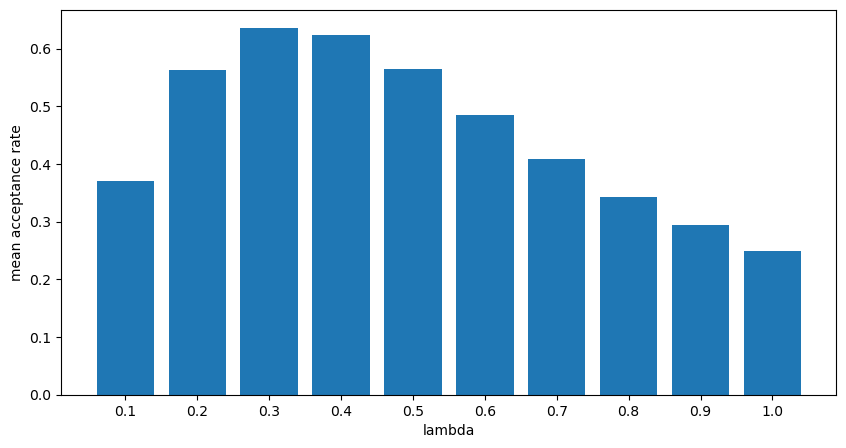

In [3]:
ave_rates = []
lambs = np.arange(0.1,1.1,0.1)  
for i in lambs:
    states,rates = metropolis_hasting(100000,i)
    ave_rates.append(np.mean(rates))
    
plt.figure(figsize=(10, 5))
plt.bar(lambs, ave_rates, width=0.08)
plt.xlabel('lambda')
plt.ylabel('mean acceptance rate')
plt.xticks(lambs)
        

Values with the highest acceptance rates ratio is around 0.2 to 0.5, we will test that range, with step size 0.03, with 10^5 iteration each. Since the acceptance rate difference is very small, a scatter and line plot was added to accentuate the difference. The chosen value is the value with the highest acceptance rate (varies with each run). However, after several runs, the best lambda chosen is consistently 0.32 and 0.35, so the range should be 0.035 +- 0.05

The best lambda value is 0.35


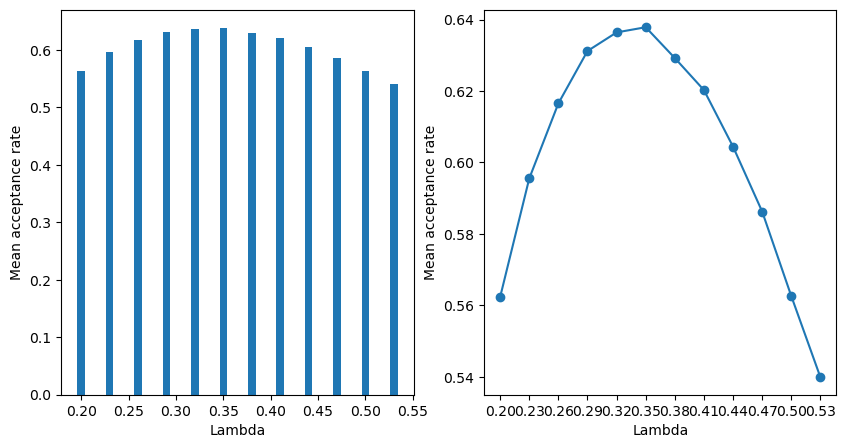

In [4]:
ave_rates = []
lambs = np.arange(0.2,0.53,0.03)  
for i in lambs:
    states,rates = metropolis_hasting(100000,i)
    ave_rates.append(np.mean(rates))

best_lamb = lambs[np.argmax(ave_rates)]
print(f'The best lambda value is {best_lamb:.2f}')

fig,axs = plt.subplots(1,2,figsize=(10, 5))
axs.flatten()

axs[0].bar(lambs, ave_rates, width=0.008)
axs[0].set_xlabel('Lambda')
axs[0].set_ylabel('Mean acceptance rate')

axs[1].scatter(lambs,ave_rates)
axs[1].plot(lambs,ave_rates)
axs[1].set_xlabel('Lambda')
axs[1].set_ylabel('Mean acceptance rate')
axs[1].set_xticks(lambs, [f'{l:.2f}' for l in lambs])
        

### b) Simulate Gamma Distribution Ga(3,1) using the best proposal distribution

(0.0, 15.0)

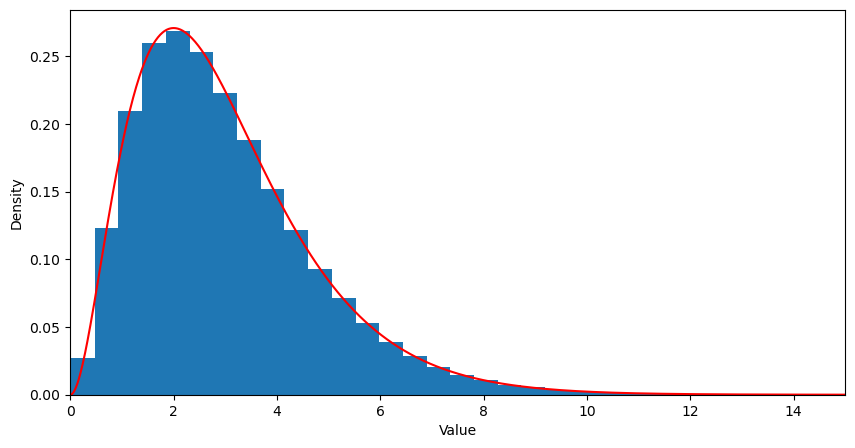

In [5]:
lamb = best_lamb
states,rates = metropolis_hasting(10**6,lamb)

# Prepare the Gamma Distribution Ga(3,1) for plotting
from scipy.stats import gamma
x = np.linspace(0, 15, 1000)
gamma = gamma.pdf(x, a=3, scale=1)

plt.figure(figsize = (10,5))
plt.hist(states, bins = 40,density=True)
plt.plot(x, gamma,'r')
plt.xlabel('Value')
plt.ylabel('Density')
plt.xlim(0,15)


### c) Compute and print the numerical values for mean and variance for the resulting distribution

In [6]:
print(f'Resulting mean: {np.mean(states):.3f}')
print(f'Resulting variance: {np.var(states):.3f}')

Resulting mean: 3.001
Resulting variance: 3.015


### d)
Metropolis-Hastings requires less information and is more generally applicable. It only needs the target density up to a normalizing constant (to evaluate the acceptance ratio), whereas the Gibbs sampler needs the full conditional distributions of each variable in closed form to sample from them directly, which aren’t usually available.